In [1]:
%load_ext autoreload
%autoreload 2
from mg_sampling import PROJECT_DIR
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from ast import literal_eval
import itertools
from functools import reduce
from mg_sampling.tools import bayesian_bootstrap, read_plumed

### Motifs

In [2]:
def motif_latex_name(x):
    names = x['inner_names']
    resnames = x['inner_resnames']
    resids = x['inner_resids']
    mgrna = x['mgrna']
    motif = ",".join(f"{resname}^{{{resid}}}_\mathrm{{{name}}}" for resname, resid, name in zip(resnames, resids, names))
    if mgrna:
        motif += '-' + mgrna
    return motif

def motif_name(x):
    names = x['inner_names']
    resnames = x['inner_resnames']
    resids = x['inner_resids']
    mgrna = x['mgrna']
    motif = ",".join(f"{resname}{resid}{name}" for resname, resid, name in zip(resnames, resids, names))
    if mgrna:
        motif += '-' + mgrna
    return motif

def label_disjoint_sets(sets):
    """
    From a list of sets, find group membership such that
    non-disjoint sets belong to the same group.
    """
    from scipy.cluster.hierarchy import DisjointSet
    # Groupping by non-empty intersection
    # In: a list of sets {a, b, c}, {d, e}, {e, f}, {a}, {g, h}...
    # Out: a list of group id such as sets with non-null intersection belong to the same group
    #      0, 1, 1, 0, 2 ...
    # Algo: list elements a, b, c, d, e, f, g, ...
    #       assign different group ids
    #       for each pair of sets, if s1 & s2 != 0, set all elements of s1 | s2 to the leftmost id

    ds = DisjointSet()
    for s in sets:
        for x in s:
            ds.add(x)
            ds.merge(x, s[0])
    
    group_ids = [ds._parents[s[0]] for s in sets]
    _, group_ids = np.unique(group_ids, return_inverse=True)

    return group_ids

In [32]:
def summarize_motifs(df):
    df['motif'] = df.apply(motif_name, axis=1).astype('category')

    # Create a unique id for each block of data for error estimate
    df['block'], _ = pd.factorize(df[['replicate', 'repid']].apply(tuple, axis=1))

    count = df.groupby(['block', 'time', 'motif'], observed=True).size()
    count = count.unstack('motif', fill_value=0)

    p_block = count.groupby('block').mean()

    p = p_block.mean().rename('p')

    # Error estimate: bayesian bootstrap with blocks
    ci = p_block.apply(
        lambda x: tuple(map(float, bayesian_bootstrap(x, np.average).confidence_interval))
    ).transpose().set_axis(['p_low', 'p_high'], axis=1)

    n_block_obs = (p_block > 0).sum().rename('n_block_obs')

    res = pd.concat([p, ci, n_block_obs], axis=1)

    res = res.join(
        df.drop_duplicates(subset='motif', keep='first').set_index('motif')[['n_inner', 'inner_indices', 'inner_names', 'inner_resids', 'inner_resnames', 'stereo', 'mgrna']]
    )

    mg_indices = df.groupby('motif', observed=True)['index'].agg(lambda x: list(set(x))).rename('mg_indices')
    res = res.join(mg_indices)

    return res


In [33]:
# Replex
t_start = 50000  # ps
t_end = 200000 # ps
systems = ['7ez0', '7ez0_noion']
replicates = [0, 1]
repids = range(8)

for sys in systems:
    df = pd.DataFrame()
    for rep, i in itertools.product(replicates, repids):
        _df = pd.read_parquet(PROJECT_DIR / f'replex/{sys}/mMg_tip3p/replicate{rep}/rep{i+8*rep:02d}/MG_motifs.parquet').assign(replicate=rep, repid=i)
        colvar = read_plumed(PROJECT_DIR / f'replex/{sys}/mMg_tip3p/replicate{rep}/rep{i+8*rep:02d}/bias.COLVAR.{i}')
        colvar['time'] = colvar['time'].astype(int)
        _df['reptemp'] = colvar.set_index('time').loc[_df['time'].astype(int), 'bias.index'].astype(int).values
        _df = _df.query('time >= @t_start and time < @t_end')
        df = pd.concat([df, _df])

    # Multiplexing and analysis
    for λ in range(8):
        res = summarize_motifs(df.query('reptemp == @λ').copy())
        res.to_parquet(PROJECT_DIR / f'replex/{sys}/mMg_tip3p/MG_motifs_summary_lambda{λ}.parquet')

In [34]:
# Plain MD
t_start = 150000  # ps
t_end = 500000 # ps
systems = ['7ez0', '7ez0_noion']
forcefields = ['mMg_tip3p', 'nMg_tip3p', 'nMg_tip3p_soft']
replicates = range(8)

for sys, ff in itertools.product(systems, forcefields):
    df = pd.DataFrame()
    for rep in replicates:
        try:
            _df = pd.read_parquet(PROJECT_DIR / f'plain_md/{sys}/{ff}/rep{rep:02d}/MG_motifs.parquet').assign(replicate=rep, repid=0)
        except FileNotFoundError as e:
            break
        _df = _df.query('time >= @t_start and time < @t_end')
        df = pd.concat([df, _df])
    else:
        res = summarize_motifs(df)
        res.to_parquet(PROJECT_DIR / f'plain_md/{sys}/{ff}/MG_motifs_summary.parquet')

res

,p,p_low,p_high,n_block_obs,n_inner,inner_indices,inner_names,inner_resids,inner_resnames,stereo,mgrna,mg_indices
motif,,,,,,,,,,,,
,144.001429,1.424226e+02,145.813716,8,0,[],[],[],[],,,"[269531, 269532, 269533, 269534, 269535, 26953..."
"A103HO'2,A104O2P-cis-OphX",0.000036,1.580539e-06,0.000113,1,2,"[2636, 2640]","[HO'2, O2P]","[103, 104]","[A, A]",cis,cis-OphX,[269626]
A103O1P-Oph,0.052821,7.229868e-03,0.162144,3,1,[2606],[O1P],[103],[A],,Oph,"[269660, 269654, 269687]"
A103O2P-Oph,0.130071,1.159584e-02,0.393915,2,1,[2607],[O2P],[103],[A],,Oph,"[269602, 269694]"
A104O1P-Oph,0.179786,2.013336e-02,0.451994,3,1,[2639],[O1P],[104],[A],,Oph,"[269625, 269690, 269615]"
...,...,...,...,...,...,...,...,...,...,...,...,...
U80O2P-Oph,0.036214,2.034799e-03,0.134167,1,1,[1867],[O2P],[80],[U],,Oph,[269596]
U84O1P-Oph,0.048643,7.931320e-03,0.101838,2,1,[1995],[O1P],[84],[U],,Oph,"[269570, 269662]"
U84O2P-Oph,0.100571,2.751954e-02,0.203847,3,1,[1996],[O2P],[84],[U],,Oph,"[269705, 269594, 269572]"


In [35]:
from ast import literal_eval
# Reference: 7ez0

df = pd.read_csv(PROJECT_DIR / f'structures/7ez0/mMg_tip3p/MG_motifs.csv')
df = df.map(lambda x: literal_eval(x) if isinstance(x, str) and x.startswith(('[','{')) else x)
res = summarize_motifs(df.query('n_inner > 0').copy().assign(replicate=0, repid=0))
res.to_parquet(PROJECT_DIR / f'structures/7ez0/mMg_tip3p/MG_motifs_summary.parquet')


In [36]:
# Reference: 9cbu

df = pd.read_csv(PROJECT_DIR / f'structures/9cbu/MG_motifs.csv')
df = df.map(lambda x: literal_eval(x) if isinstance(x, str) and x.startswith(('[','{')) else x)
res = summarize_motifs(df.query('n_inner > 0').copy().assign(replicate=0, repid=0))
res.to_parquet(PROJECT_DIR / f'structures/9cbu/MG_motifs_summary.parquet')


In [37]:
res

,p,p_low,p_high,n_block_obs,n_inner,inner_indices,inner_names,inner_resids,inner_resnames,stereo,mgrna,mg_indices
motif,,,,,,,,,,,,
"A183OP1,A184OP2,A186OP2-fac-3Oph",1.0,1.0,1.0,1,3,"[5196, 5230, 5293]","[OP1, OP2, OP2]","[183, 184, 186]","[A, A, A]",fac,fac-3Oph,[12446]
"A184OP1,A186OP1,A187OP2-fac-3Oph",1.0,1.0,1.0,1,3,"[5229, 5292, 5326]","[OP1, OP1, OP2]","[184, 186, 187]","[A, A, A]",fac,fac-3Oph,[12447]
A187OP1-Oph,1.0,1.0,1.0,1,1,[5325],[OP1],[187],[A],NaN,Oph,[12461]
"A256OP1,U273OP1-cis-2Oph",1.0,1.0,1.0,1,2,"[7534, 8080]","[OP1, OP1]","[256, 273]","[A, U]",cis,cis-2Oph,[12451]
"A261N7,A265OP2,A306H61-fac-OphNbX",1.0,1.0,1.0,1,3,"[7713, 7824, 9160]","[N7, OP2, H61]","[261, 265, 306]","[A, A, A]",fac,fac-OphNbX,[12453]
"A270H2',A270HO2',G272O6-fac-Ob2X",1.0,1.0,1.0,1,3,"[7996, 7998, 8070]","[H2', HO2', O6]","[270, 270, 272]","[A, A, G]",fac,fac-Ob2X,[12459]
"A270H4',U271OP1-cis-OphX",1.0,1.0,1.0,1,2,"[7990, 8016]","[H4', OP1]","[270, 271]","[A, U]",cis,cis-OphX,[12464]
"A301OP1,A302OP2-cis-2Oph",1.0,1.0,1.0,1,2,"[8972, 9006]","[OP1, OP2]","[301, 302]","[A, A]",cis,cis-2Oph,[12448]
"A304OP1,A306OP1-cis-2Oph",1.0,1.0,1.0,1,2,"[9072, 9135]","[OP1, OP1]","[304, 306]","[A, A]",cis,cis-2Oph,[12452]


### Plot most frequent motifs

In [11]:
# Collect all motifs summaries

res = pd.DataFrame()

# Replex
systems = ['7ez0', '7ez0_noion']
for sys in systems:
    _res = pd.read_parquet(PROJECT_DIR / f'replex/{sys}/mMg_tip3p/MG_motifs_summary_lambda0.parquet').assign(sim=f'replex_{sys}_mMg_tip3p')
    res = pd.concat([res, _res])

# PlainMD
systems = ['7ez0', '7ez0_noion']
forcefields = ['mMg_tip3p', 'nMg_tip3p', 'nMg_tip3p_soft']
for sys, ff in itertools.product(systems, forcefields):
    try:
        _res = pd.read_parquet(PROJECT_DIR / f'plain_md/{sys}/{ff}/MG_motifs_summary.parquet').assign(sim=f'plain_md_{sys}_{ff}')
    except FileNotFoundError:
        pass
    else:
        res = pd.concat([res, _res])

# References
_res = pd.read_parquet(PROJECT_DIR / f'structures/7ez0/mMg_tip3p/MG_motifs_summary.parquet').assign(sim=f'7ez0')
res = pd.concat([res, _res])
# _res = pd.read_parquet(PROJECT_DIR / f'structures/9cbu/MG_motifs_summary.parquet').assign(sim=f'9cbu')
# res = pd.concat([res, _res])
res = res.drop(index="")
res['inner_labels'] = res.apply(lambda x: [f"{resname}{resid}{name}" for resname, resid, name in zip(x['inner_resnames'], x['inner_resids'], x['inner_names'])], axis=1)
res['motif_group'] = label_disjoint_sets(res['inner_labels'])

In [14]:
res.sort_values('p', ascending=False)

,p,p_low,p_high,n_block_obs,n_inner,inner_indices,inner_names,inner_resids,inner_resnames,stereo,mgrna,sim,inner_labels,motif_group
motif,,,,,,,,,,,,,,
U258O1P-Oph,1.000000,1.000000e+00,1.000000,1,1,[7598],[O1P],[258],[U],None,Oph,7ez0,[U258O1P],600
U259O1P-Oph,1.000000,1.000000e+00,1.000000,1,1,[7628],[O1P],[259],[U],None,Oph,7ez0,[U259O1P],601
"A184O1P,A186O1P,A187O2P-fac-3Oph",1.000000,1.000000e+00,1.000000,1,3,"[5226, 5289, 5323]","[O1P, O1P, O2P]","[184, 186, 187]","[A, A, A]",fac,fac-3Oph,7ez0,"[A184O1P, A186O1P, A187O2P]",41
"A183O1P,A184O2P,A186O2P-fac-3Oph",1.000000,1.000000e+00,1.000000,1,3,"[5193, 5227, 5290]","[O1P, O2P, O2P]","[183, 184, 186]","[A, A, A]",fac,fac-3Oph,7ez0,"[A183O1P, A184O2P, A186O2P]",41
"A172O2P,A173O2P-cis-2Oph",1.000000,1.000000e+00,1.000000,1,2,"[4835, 4868]","[O2P, O2P]","[172, 173]","[A, A]",cis,cis-2Oph,7ez0,"[A172O2P, A173O2P]",37
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
"A207O1P,A207H5'2,C262O2P-fac-2OphX",0.000036,1.887061e-06,0.000128,1,3,"[5966, 5971, 7723]","[O1P, H5'2, O2P]","[207, 207, 262]","[A, A, C]",fac,fac-2OphX,plain_md_7ez0_nMg_tip3p_soft,"[A207O1P, A207H5'2, C262O2P]",108
"A125H5'1,G126O2P-cis-OphX",0.000036,1.263001e-06,0.000131,1,2,"[3329, 3359]","[H5'1, O2P]","[125, 126]","[A, G]",cis,cis-OphX,plain_md_7ez0_nMg_tip3p_soft,"[A125H5'1, G126O2P]",361
A123O2P-Oph,0.000036,5.743269e-07,0.000117,1,1,[3262],[O2P],[123],[A],,Oph,plain_md_7ez0_nMg_tip3p_soft,[A123O2P],13


In [20]:
# Show the most interesting motifs:
# First all PDB 7ez0 ones
motifs_7ez0 = res.query('sim == "7ez0"').sort_values('inner_indices', key=lambda col: col.map(lambda x: x[0]))
motifs_7ez0

,p,p_low,p_high,n_block_obs,n_inner,inner_indices,inner_names,inner_resids,inner_resnames,stereo,mgrna,sim,inner_labels,motif_group
motif,,,,,,,,,,,,,,
G149O2P-Oph,1.0,1.0,1.0,1,1,[4095],[O2P],[149],[G],None,Oph,7ez0,[G149O2P],373
"G163N7,G164O6-cis-ObNb",1.0,1.0,1.0,1,2,"[4560, 4597]","[N7, O6]","[163, 164]","[G, G]",cis,cis-ObNb,7ez0,"[G163N7, G164O6]",380
A171O2P-Oph,1.0,1.0,1.0,1,1,[4802],[O2P],[171],[A],None,Oph,7ez0,[A171O2P],35
"A172O2P,A173O2P-cis-2Oph",1.0,1.0,1.0,1,2,"[4835, 4868]","[O2P, O2P]","[172, 173]","[A, A]",cis,cis-2Oph,7ez0,"[A172O2P, A173O2P]",37
"A183O1P,A184O2P,A186O2P-fac-3Oph",1.0,1.0,1.0,1,3,"[5193, 5227, 5290]","[O1P, O2P, O2P]","[183, 184, 186]","[A, A, A]",fac,fac-3Oph,7ez0,"[A183O1P, A184O2P, A186O2P]",41
"A184O1P,A186O1P,A187O2P-fac-3Oph",1.0,1.0,1.0,1,3,"[5226, 5289, 5323]","[O1P, O1P, O2P]","[184, 186, 187]","[A, A, A]",fac,fac-3Oph,7ez0,"[A184O1P, A186O1P, A187O2P]",41
"A207O1P,C262O2P-cis-2Oph",1.0,1.0,1.0,1,2,"[5966, 7723]","[O1P, O2P]","[207, 262]","[A, C]",cis,cis-2Oph,7ez0,"[A207O1P, C262O2P]",108
A214O2P-Oph,1.0,1.0,1.0,1,1,[6191],[O2P],[214],[A],None,Oph,7ez0,[A214O2P],56
"A256O1P,U273O1P-cis-2Oph",1.0,1.0,1.0,1,2,"[7531, 8077]","[O1P, O1P]","[256, 273]","[A, U]",cis,cis-2Oph,7ez0,"[A256O1P, U273O1P]",81


In [81]:

# Then N motifs with highest ci.low
N = 40 - len(motifs_7ez0)
best_motifs = res.query('sim != "7ez0" and motif != "" and n_inner > 1').sort_values(by='ci', key=lambda col: col.map(lambda x: x[0]), ascending=False)['motif']
best_N_motifs = best_motifs[~best_motifs.isin(motifs_7ez0)][:N]


In [82]:
motifs = pd.concat([motifs_7ez0, best_N_motifs])
motifs

3460                     A207O1P,C262O2P-cis-2Oph
3459             A184O1P,A186O1P,A187O2P-fac-3Oph
3458             A183O1P,A184O2P,A186O2P-fac-3Oph
3466                       G163N7,G164O6-cis-ObNb
3465                                  G149O2P-Oph
3462                     A256O1P,U273O1P-cis-2Oph
3461                                  A214O2P-Oph
3467    G257O1P,U258O2P,C260O2,U305O2P-Cis-3OphOb
3468                                  U258O1P-Oph
3469                                  U259O1P-Oph
3470                                  U305O1P-Oph
3463                     A301O1P,A302O2P-cis-2Oph
3456                                  A171O2P-Oph
3457                     A172O2P,A173O2P-cis-2Oph
3464                     A304O1P,A306O1P-cis-2Oph
3471                     U307O2P,A308O2P-cis-2Oph
1636     A184O1P,A186O1P,A187O2P,G188O2P-Cis-4Oph
1506     A184O1P,A186O1P,A187O2P,G188O2P-Cis-4Oph
0        A184O1P,A186O1P,A187O2P,G188O2P-Cis-4Oph
2209     A184O1P,A186O1P,A187O2P,G188O2P-Cis-4Oph


In [83]:
motifs

3460                     A207O1P,C262O2P-cis-2Oph
3459             A184O1P,A186O1P,A187O2P-fac-3Oph
3458             A183O1P,A184O2P,A186O2P-fac-3Oph
3466                       G163N7,G164O6-cis-ObNb
3465                                  G149O2P-Oph
3462                     A256O1P,U273O1P-cis-2Oph
3461                                  A214O2P-Oph
3467    G257O1P,U258O2P,C260O2,U305O2P-Cis-3OphOb
3468                                  U258O1P-Oph
3469                                  U259O1P-Oph
3470                                  U305O1P-Oph
3463                     A301O1P,A302O2P-cis-2Oph
3456                                  A171O2P-Oph
3457                     A172O2P,A173O2P-cis-2Oph
3464                     A304O1P,A306O1P-cis-2Oph
3471                     U307O2P,A308O2P-cis-2Oph
1636     A184O1P,A186O1P,A187O2P,G188O2P-Cis-4Oph
1506     A184O1P,A186O1P,A187O2P,G188O2P-Cis-4Oph
0        A184O1P,A186O1P,A187O2P,G188O2P-Cis-4Oph
2209     A184O1P,A186O1P,A187O2P,G188O2P-Cis-4Oph


In [84]:
sorter = list(motifs)
out = res.loc[res['motif'].isin(motifs)].copy()
out['motif'] = out['motif'].astype('category')
out = out.groupby(['motif', 'sim'], observed=False)['proba'].sum().unstack().loc[sorter].stack()
out.loc[out == 0] = np.nan


In [85]:
out

motif                     sim                          
A207O1P,C262O2P-cis-2Oph  7ez0                             1.000000
                          plain_md_7ez0_mMg_tip3p          0.925107
                          plain_md_7ez0_nMg_tip3p          0.722464
                          plain_md_7ez0_nMg_tip3p_soft     0.353357
                          plain_md_7ez0_noion_nMg_tip3p    0.079571
                                                             ...   
G346O2P,U348O1P-cis-2Oph  plain_md_7ez0_nMg_tip3p          0.097679
                          plain_md_7ez0_nMg_tip3p_soft     0.066607
                          plain_md_7ez0_noion_nMg_tip3p         NaN
                          replex_7ez0_mMg_tip3p            0.198000
                          replex_7ez0_noion_mMg_tip3p      0.225000
Length: 280, dtype: float64

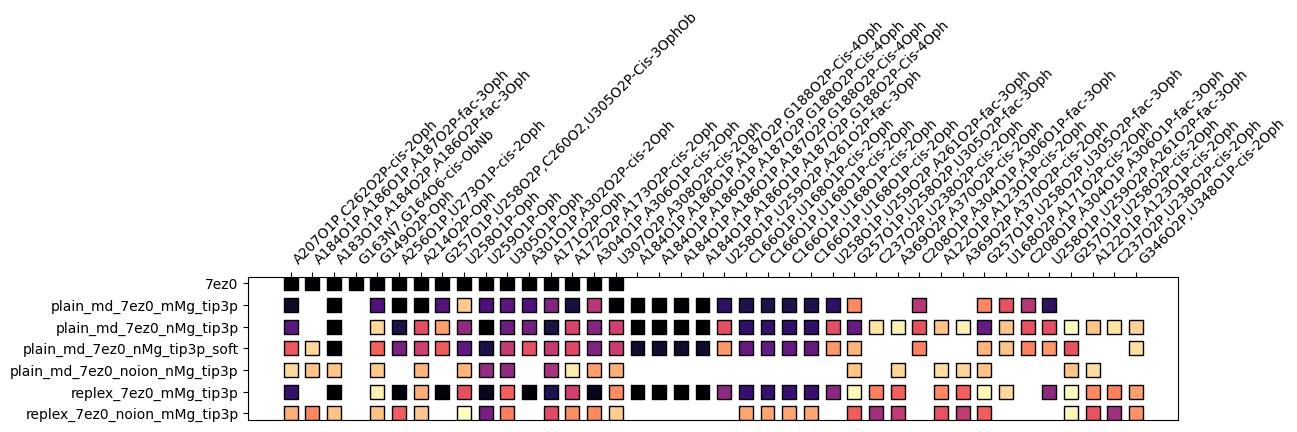

In [475]:
fig, ax = plt.subplots(figsize=(12, 4))

ax.scatter(
    np.arange(len(motifs)).repeat(len(sims)),
    np.tile(np.arange(len(sims)), len(motifs)),
    c=out,
    marker='s',
    edgecolors='black',
    s=100,
    cmap='magma_r',
)
ax.invert_yaxis()
ax.set_aspect(1)
ax.set_yticks(np.arange(len(sims)), labels=sims)
ax.set_xticks(np.arange(len(motifs)), labels=motifs, rotation=45, ha='left')
ax.tick_params(top=True, labeltop=True, bottom=False, labelbottom=False)

In [284]:
out.max()

np.float64(1.9847142857142857)

<Axes: xlabel='n_inner', ylabel='%'>

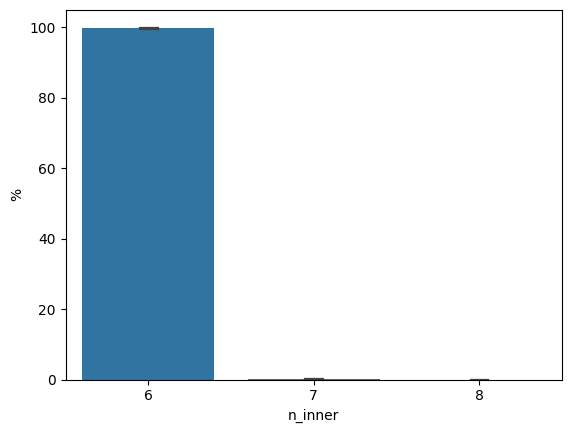

In [67]:
sns.barplot(
    x,
    x='n_inner',
    y='%',
    errorbar=_agg,
    capsize=0.1,
)

In [ ]:
def _plot(data, **kws):
    x = data.groupby(['frame', 'n_inner]').size()
    res = bayesian_bootstrap(x, np.average)

,frame,time,index,name,n_inner,inner_indices,inner_names,inner_resids,inner_resnames,stereo,mgrna,n_outer,outer_indices,outer_names,outer_resids,outer_resnames
0,0,0.0,12442,MG,6,"[161881, 161920, 162001, 162169, 162172, 165331]","[OW, OW, OW, OW, OW, OW]","[50332, 50345, 50372, 50428, 50429, 51482]","[SOL, SOL, SOL, SOL, SOL, SOL]",,6Ow,16,"[2844, 2845, 2846, 2847, 2878, 128323, 157705,...","[N7, C5, C6, O6, N7, OW, OW, OW, OW, OW, OW, O...","[110, 110, 110, 110, 111, 39146, 48940, 49853,...","[G, G, G, G, G, SOL, SOL, SOL, SOL, SOL, SOL, ..."
1,0,0.0,12443,MG,6,"[5966, 7723, 139471, 139486, 161701, 164926]","[O1P, O2P, OW, OW, OW, OW]","[207, 262, 42862, 42867, 50272, 51347]","[A, C, SOL, SOL, SOL, SOL]",,2Oph4Ow,29,"[5938, 5958, 5959, 5964, 5965, 5967, 5968, 596...","[H5'2, C3', H3', O3', P, O2P, O5', C5', H5'1, ...","[206, 206, 206, 206, 207, 207, 207, 207, 207, ...","[A, A, A, A, A, A, A, A, A, A, A, A, A, C, C, ..."
2,0,0.0,12444,MG,6,"[2966, 161659, 161692, 161779, 161794, 161815]","[O2P, OW, OW, OW, OW, OW]","[114, 50258, 50269, 50298, 50303, 50310]","[A, SOL, SOL, SOL, SOL, SOL]",,Oph5Ow,22,"[2957, 2958, 2959, 2960, 2963, 2964, 2965, 296...","[C3', H3', C2', H2'1, O3', P, O1P, O5', O4, N6...","[113, 113, 113, 113, 113, 114, 114, 114, 205, ...","[A, A, A, A, A, A, A, A, U, A, A, A, A, SOL, S..."
3,0,0.0,12445,MG,6,"[5226, 5289, 5323, 5356, 161914, 162469]","[O1P, O1P, O2P, O2P, OW, OW]","[184, 186, 187, 188, 50343, 50528]","[A, A, A, G, SOL, SOL]",,4Oph2Ow,43,"[5193, 5196, 5198, 5224, 5225, 5227, 5228, 522...","[O1P, C5', H5'2, O3', P, O2P, O5', C5', H5'1, ...","[183, 183, 183, 183, 184, 184, 184, 184, 184, ...","[A, A, A, A, A, A, A, A, A, A, U, U, U, U, A, ..."
4,0,0.0,12446,MG,6,"[5193, 5227, 5290, 162103, 162292, 162328]","[O1P, O2P, O2P, OW, OW, OW]","[183, 184, 186, 50406, 50469, 50481]","[A, A, A, SOL, SOL, SOL]",,3Oph3Ow,32,"[5191, 5192, 5194, 5195, 5196, 5198, 5206, 521...","[O3', P, O2P, O5', C5', H5'2, H8, C3', H3', O3...","[182, 183, 183, 183, 183, 183, 183, 183, 183, ...","[U, A, A, A, A, A, A, A, A, A, A, A, A, A, A, ..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
106973,6000,600000.0,269926,MG,6,"[37975, 215326, 259411, 259705, 259843, 263035]","[OW, OW, OW, OW, OW, OW]","[9030, 68147, 82842, 82940, 82986, 84050]","[SOL, SOL, SOL, SOL, SOL, SOL]",,6Ow,28,"[9356, 9357, 9362, 9390, 9391, 9392, 9441, 944...","[P, O1P, H5'2, P, O1P, O2P, N4, H41, H42, H42,...","[313, 313, 313, 314, 314, 314, 315, 315, 315, ...","[G, G, G, A, A, A, C, C, C, C, G, G, G, G, G, ..."
106974,6000,600000.0,269927,MG,6,"[103939, 144529, 230854, 231124, 243268, 261610]","[OW, OW, OW, OW, OW, OW]","[31018, 44548, 73323, 73413, 77461, 83575]","[SOL, SOL, SOL, SOL, SOL, SOL]",,6Ow,11,"[14080, 24490, 27046, 42865, 49780, 90766, 119...","[OW, OW, OW, OW, OW, OW, OW, OW, OW, OW, OW]","[1065, 4535, 5387, 10660, 12965, 26627, 36240,...","[SOL, SOL, SOL, SOL, SOL, SOL, SOL, SOL, SOL, ..."
106975,6000,600000.0,269928,MG,6,"[976, 49951, 96634, 263422, 263533, 263755]","[O2P, OW, OW, OW, OW, OW]","[52, 13022, 28583, 84179, 84216, 84290]","[U, SOL, SOL, SOL, SOL, SOL]",,Oph5Ow,24,"[240, 266, 268, 940, 941, 942, 943, 944, 946, ...","[H5'2, O3', O1P, P, O1P, O2P, O5', C5', H5'2, ...","[29, 29, 30, 51, 51, 51, 51, 51, 51, 51, 51, 5...","[A, A, A, G, G, G, G, G, G, G, G, G, U, U, U, ..."
106976,6000,600000.0,269929,MG,6,"[116674, 231862, 263404, 263461, 263527, 263728]","[OW, OW, OW, OW, OW, OW]","[35263, 73659, 84173, 84192, 84214, 84281]","[SOL, SOL, SOL, SOL, SOL, SOL]",,6Ow,20,"[555, 560, 588, 589, 590, 647, 651, 652, 653, ...","[O1P, H5'2, P, O1P, O2P, H3', HO'2, O3', P, O1...","[39, 39, 40, 40, 40, 41, 41, 41, 42, 42, 42, 5...","[G, G, G, G, G, C, C, C, A, A, A, SOL, SOL, SO..."


In [2]:
# Replex
systems = ['7ez0']
forcefields = ['mMg_tip3p']
replicates = [0]
repids = [0, 7]
ions = ['MG']

df = pd.DataFrame()
for system, forcefield, replicate, repid, ion in itertools.product(systems, forcefields, replicates, repids, ions):
    path = PROJECT_DIR / 'replex' / system / forcefield / f'replicate{replicate}' / f'rep{repid:02d}'
    _df = pd.read_csv(path / f'{ion}_OW_motifs.csv', na_filter=False, usecols=['time', 'index', 'n_inner', 'mgrna'])
    _df['system'] = system
    _df['forcefield'] = forcefield
    _df['repid'] = int(repid)
    _df['replicate'] = replicate
    _df['method'] = 'replex'
    df = pd.concat([df, _df])

# PlainMD
systems = ['7ez0']
forcefields = ['mMg_tip3p', 'nMg_tip3p']
replicates = range(8)
ions = ['MG']

for system, forcefield, replicate, repid, ion in itertools.product(systems, forcefields, replicates, repids, ions):
    try:
        path = PROJECT_DIR / 'plain_md' / system / forcefield / f'rep{replicate:02d}'
        _df = pd.read_csv(path / f'{ion}_OW_motifs.csv', na_filter=False, usecols=['time', 'index', 'n_inner', 'mgrna'])
        _df['system'] = system
        _df['forcefield'] = forcefield
        _df['replicate'] = replicate
        _df['method'] = 'plain_md'
        df = pd.concat([df, _df])
    except FileNotFoundError as e:
        print(e)
        pass

for col in ['mgrna', 'forcefield', 'system', 'method']:
    df[col] = df[col].astype('category')

In [3]:
df['repid'] = df['repid'].fillna(0).astype(int)
df['sim'] = df['method'].str.cat(df['forcefield'], sep='_').str.cat(df['repid'].astype(str), sep='_')
df['sim'] = df['sim'].map({
    'replex_mMg_tip3p_0': 'μMg (REx, $λ_0$)',
    'replex_mMg_tip3p_7': 'μMg (REx, $λ_7$)',
    'plain_md_mMg_tip3p_0': 'μMg (MD)',
    'plain_md_nMg_tip3p_0': 'nMg (MD)',
})

In [8]:
df.head()

,time,index,n_inner,mgrna,system,forcefield,repid,replicate,method,sim
0,0.0,12442,6,6Ow,7ez0,mMg_tip3p,0,0,replex,"μMg (REx, $λ_0$)"
1,0.0,12443,6,2Oph4Ow,7ez0,mMg_tip3p,0,0,replex,"μMg (REx, $λ_0$)"
2,0.0,12444,6,Oph5Ow,7ez0,mMg_tip3p,0,0,replex,"μMg (REx, $λ_0$)"
3,0.0,12445,6,4Oph2Ow,7ez0,mMg_tip3p,0,0,replex,"μMg (REx, $λ_0$)"
4,0.0,12446,6,3Oph3Ow,7ez0,mMg_tip3p,0,0,replex,"μMg (REx, $λ_0$)"


In [ ]:
palette = ['tomato', 'darkred', 'gray', 'mediumpurple']
labels = ['μMg (REx, $λ_0$)', 'μMg (REx, $λ_7$)', 'μMg (MD)', 'nMg (MD)']

tstart_replex = 50000  # ps
tstart_plain_md = 150000
grouped = df.query(f"(method == 'replex' and time >= {tstart_replex}) or (method == 'plain_md' and time >= {tstart_plain_md})")

sns.set_style("ticks", {'axes.grid': True})



[((np.int64(6), 'nMg (MD)', np.int64(0)),
  time      n_inner  sim       replicate
  150000.0  6        nMg (MD)  0            354
  151000.0  6        nMg (MD)  0            354
  152000.0  6        nMg (MD)  0            356
  153000.0  6        nMg (MD)  0            356
  154000.0  6        nMg (MD)  0            356
                                           ... 
  596000.0  6        nMg (MD)  0            354
  597000.0  6        nMg (MD)  0            354
  598000.0  6        nMg (MD)  0            356
  599000.0  6        nMg (MD)  0            354
  600000.0  6        nMg (MD)  0            352
  Length: 451, dtype: int64),
 ((np.int64(6), 'nMg (MD)', np.int64(1)),
  time      n_inner  sim       replicate
  150000.0  6        nMg (MD)  1            356
  151000.0  6        nMg (MD)  1            352
  152000.0  6        nMg (MD)  1            354
  153000.0  6        nMg (MD)  1            354
  154000.0  6        nMg (MD)  1            352
                                    

KeyError: 'time'

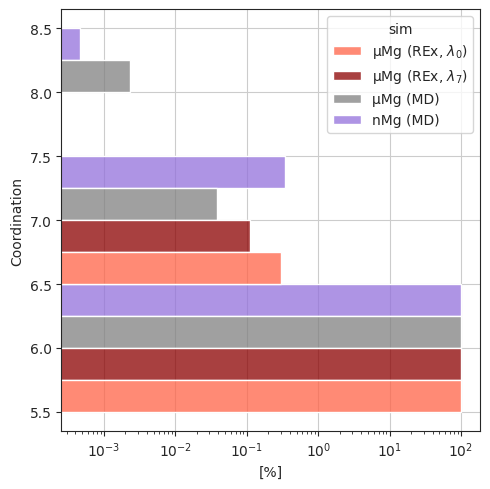

In [24]:
palette = ['tomato', 'darkred', 'gray', 'mediumpurple']
labels = ['μMg (REx, $λ_0$)', 'μMg (REx, $λ_7$)', 'μMg (MD)', 'nMg (MD)']

tstart_replex = 50000  # ps
tstart_plain_md = 150000
grouped = df.query(f"(method == 'replex' and time >= {tstart_replex}) or (method == 'plain_md' and time >= {tstart_plain_md})")

sns.set_style("ticks", {'axes.grid': True})

ax = sns.histplot(grouped,
    y='n_inner',
    hue='sim',
    hue_order=labels,
    palette=palette,
    stat='percent',
    discrete=True,
    multiple='dodge',
    common_norm=False,
)

# ax.add_legend(g._legend_data, loc='center', bbox_to_anchor=(0.5, 1), ncol=len(labels))
ax.set_xscale('log')
ax.set_xlabel("[%]")
ax.set_ylabel(r"Coordination")
plt.gcf().set_size_inches((5, 5))
plt.tight_layout()
plt.savefig('figures/average_n_inner.pdf', bbox_inches='tight')

### Inner-bound (< 2.8 Å)

In [149]:
# Replex
systems = ['7ez0', '7ez0_noion']
forcefields = ['mMg_tip3p']
replicates = [0]
repids = [0]
ions = ['MG', 'NA']

df = []
for system, forcefield, replicate, repid, ion in itertools.product(systems, forcefields, replicates, repids, ions):
    path = PROJECT_DIR / 'replex' / system / forcefield / f'replicate{replicate}' / f'rep{repid:02d}'
    _df = pd.read_csv(path / f'{ion}_motifs.csv', na_filter=False)
    _df = _df.loc[_df['time'] % 1000.0 == 0]
    _df['system'] = system
    _df['forcefield'] = forcefield
    _df['repid'] = repid
    _df['replicate'] = replicate
    _df['method'] = 'replex'
    df.append(_df)

# PlainMD
systems = ['7ez0', '7ez0_noion']
forcefields = ['nMg_tip3p_hard', 'mMg_tip3p_hard', 'nMg_tip3p']
replicates = range(8)
ions = ['MG', 'NA']

for system, forcefield, replicate, repid, ion in itertools.product(systems, forcefields, replicates, repids, ions):
    try:
        path = PROJECT_DIR / 'plain_md' / system / forcefield / f'rep{replicate:02d}'
        _df = pd.read_csv(path / f'{ion}_motifs.csv', na_filter=False)
        _df = _df.loc[_df['time'] % 1000.0 == 0]
        _df['system'] = system
        _df['forcefield'] = forcefield
        _df['replicate'] = replicate
        _df['method'] = 'plain_md'
        df.append(_df)
    except FileNotFoundError as e:
        print(e)
        pass

df = pd.concat(df)
for col in ['name', 'mgrna', 'forcefield', 'system', 'method']:
    df[col] = df[col].astype('category')


In [150]:
tstart_replex = 50000  # ps
tstart_plain_md = 150000

grouped = df.query(f"(method == 'replex' and time >= {tstart_replex}) or (method == 'plain_md' and time >= {tstart_plain_md})").groupby(
    ['time', 'name', 'n_inner', 'forcefield', 'system', 'replicate', 'method'], observed=True
    ).size().reset_index(name='counts')

In [151]:
# Compute unbound by taking the complement
n_tot = {'MG': 178, 'NA': 121}
tot = grouped.groupby(['time', 'name', 'forcefield', 'system', 'replicate', 'method'], observed=True).sum()['counts'].reset_index()
tot['tot'] = tot['name'].map(n_tot).astype(int)
tot['counts'] = tot['tot'] - tot['counts']
tot = tot.drop(columns='tot')
tot.insert(2, 'n_inner', -1)
grouped = pd.concat([grouped, tot])
grouped['sim'] = grouped['method'].str.cat(grouped['forcefield'], sep='_')
grouped['sim'] = grouped['sim'].map({
    'replex_mMg_tip3p': 'μMg (REx)',
    'plain_md_mMg_tip3p_hard': 'μMg (MD)',
    'plain_md_nMg_tip3p_hard': 'nMg (MD)',
    'plain_md_nMg_tip3p': 'nMg (MD-soft)',
})
grouped['binding'] = grouped['n_inner'].replace(-1, 'Bulk').replace(0, 'Outer')
grouped = grouped.sort_values('n_inner')

In [154]:
grouped.query("forcefield == 'nMg_tip3p'")

,time,name,n_inner,forcefield,system,replicate,method,counts,sim,binding


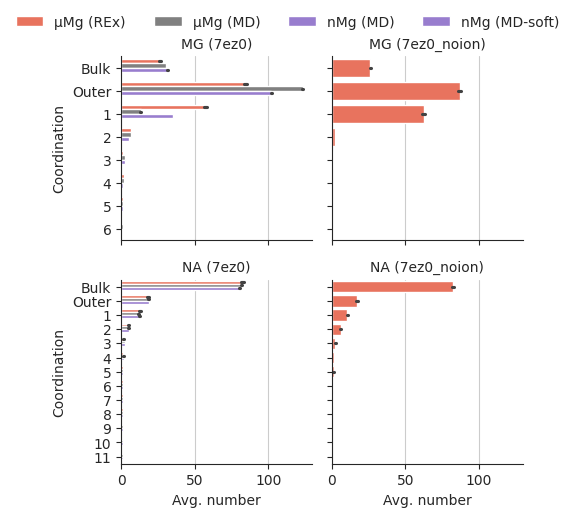

In [152]:
palette = ['tomato', 'gray', 'mediumpurple', 'mediumpurple']
labels = ['μMg (REx)', 'μMg (MD)', 'nMg (MD)', 'nMg (MD-soft)']

g = sns.FacetGrid(grouped, row='name', col='system', sharey='row')
sns.set_style("ticks", {'axes.grid': True})

g.map_dataframe(
    sns.barplot,
    y='binding',
    x='counts',
    orient='h',
    hue='sim',
    hue_order=labels,
    palette=palette,
)

g.add_legend(g._legend_data, loc='center', bbox_to_anchor=(0.5, 1), ncol=len(labels))
g.set_xlabels("Avg. number")
g.set_ylabels(r"Coordination")
g.set_titles("{row_name} ({col_name})")
plt.gcf().set_size_inches((5, 5))
plt.tight_layout()
plt.savefig('figures/average_coordination.pdf', bbox_inches='tight')

## Inner-bound sites

In [119]:
tstart_replex = 50000  # ps
tstart_plain_md = 150000

grouped = df.query(f"((method == 'replex' and time >= {tstart_replex}) or (method == 'plain_md' and time >= {tstart_plain_md})) and n_inner > 0").copy()
grouped['inner_names'] = grouped['inner_names'].map(literal_eval)

In [120]:
grouped = grouped.explode('inner_names')

In [121]:
# Count by name
grouped = grouped.groupby(['name', 'system', 'method', 'forcefield', 'inner_names'], observed=True).size()


In [124]:
grouped.groupby(['name', 'system', 'method', 'forcefield'], observed=True).sum()

name  system      method    forcefield    
MG    7ez0        plain_md  mMg_tip3p_hard    126433
                            nMg_tip3p_hard    211153
                  replex    mMg_tip3p          12377
      7ez0_noion  replex    mMg_tip3p          10230
NA    7ez0        plain_md  mMg_tip3p_hard    110244
                            nMg_tip3p_hard    140899
                  replex    mMg_tip3p           4912
      7ez0_noion  replex    mMg_tip3p           5909
dtype: int64

In [128]:
grouped = (grouped / grouped.groupby(['name', 'system', 'method', 'forcefield'], observed=True).sum())

In [132]:
grouped = grouped.reset_index(name='proportion')

In [133]:
grouped

,name,system,method,forcefield,inner_names,proportion
0,MG,7ez0,plain_md,mMg_tip3p_hard,C2,0.000032
1,MG,7ez0,plain_md,mMg_tip3p_hard,H3',0.000103
2,MG,7ez0,plain_md,mMg_tip3p_hard,H4',0.000008
3,MG,7ez0,plain_md,mMg_tip3p_hard,H5'1,0.000040
4,MG,7ez0,plain_md,mMg_tip3p_hard,H5'2,0.000340
...,...,...,...,...,...,...
195,NA,7ez0_noion,replex,mMg_tip3p,O4,0.028939
196,NA,7ez0_noion,replex,mMg_tip3p,O4',0.001354
197,NA,7ez0_noion,replex,mMg_tip3p,O5',0.028431
198,NA,7ez0_noion,replex,mMg_tip3p,O6,0.028600


array(['O2P', 'O1P', 'N7', "O2'", 'O6', 'O4', "HO'2", "O3'", 'O2', "O5'",
       'CL', 'N3', 'N1', "H5'2", "H1'", "O4'", 'H62', 'H61', 'H8', 'H22',
       "H3'", 'H42', 'H3', 'P', 'C8', 'N6', "H5'1", "H4'", "H2'1", 'C6',
       'N4', 'H2', 'H41', 'H5', 'H1', 'N2', 'H21', 'H5T', 'C5', 'C2',
       "C2'", "C4'", 'C4', 'H3T', 'H6', "C5'", "C1'"], dtype=object)

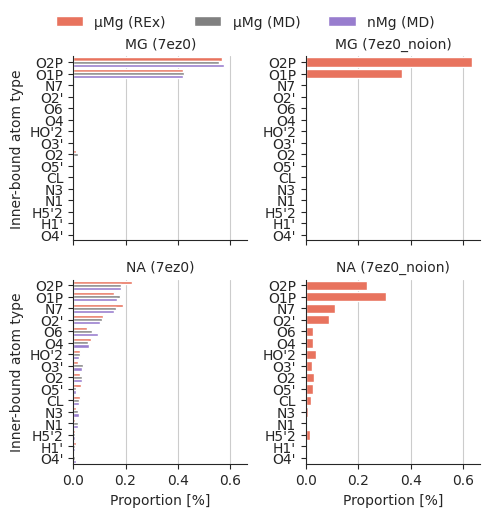

In [ ]:
grouped['sim'] = grouped['method'].str.cat(grouped['forcefield'], sep='_')
grouped['sim'] = grouped['sim'].map({
    'replex_mMg_tip3p': 'μMg (REx)',
    'plain_md_mMg_tip3p_hard': 'μMg (MD)',
    'plain_md_nMg_tip3p_hard': 'nMg (MD)',
})
palette = ['tomato', 'gray', 'mediumpurple']
labels = ['μMg (REx)', 'μMg (MD)', 'nMg (MD)']

g = sns.FacetGrid(grouped, row='name', col='system', sharey='row')
sns.set_style("ticks", {'axes.grid': True})

g.map_dataframe(
    sns.barplot,
    y='inner_names',
    x='proportion',
    orient='h',
    hue='sim',
    hue_order=labels,
    palette=palette,
    order=grouped[grouped['proportion'] > 0.01].sort_values('proportion', ascending=False)['inner_names'].unique(),
)

g.add_legend(g._legend_data, loc='center', bbox_to_anchor=(0.5, 1), ncol=len(labels))
g.set_xlabels("Proportion")
g.set_ylabels("Inner-bound atom type")
g.set_titles("{row_name} ({col_name})")
for axis in g.axes.flat:
    axis.tick_params(labelleft=True)
plt.gcf().set_size_inches((5, 5))
plt.tight_layout()
plt.savefig('figures/binding_sites.pdf', bbox_inches='tight')

### Summarize motifs